<a href="https://colab.research.google.com/github/roshelle-en/EN4554-Assignment-2-on-CNNs/blob/main/220468L_EN4554_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Department of Electronic & Telecommunication Engineering,
### University of Moratuwa, Sri Lanka.

## EN4554 - Deep Learning for Vision
## Assignment 2 on CNNs
### 220468L - Perera M.D.R.N

**GitHub Repository:** [EN4554-Assignment-2-on-CNNs](https://github.com/roshelle-en/EN4554-Assignment-2-on-CNNs)

---

# Introduction

This notebook presents my work for Assignment 2 of EN4554, implemented in PyTorch and run on a Google Colab T4 GPU. All experiments use the CIFAR-10 dataset, with the training set split into 45,000 training and 5,000 validation images, per-channel normalization using training-set statistics only, and fixed random seeds for reproducibility.

The assignment covers manual implementation of backpropagation, comparison of optimization algorithms, and the effects of regularization techniques on model performance. It also investigates the differences between plain and residual neural networks of varying depths. Finally, a compact convolutional neural network is developed and evaluated to explore design choices that improve image classification accuracy while maintaining a limited number of parameters. The experiments are evaluated using training and validation results, with visualizations and comparisons used to understand the strengths and limitations of each approach.

# Setup

This section imports the libraries, fixes the random seeds, loads CIFAR-10, splits the training set into 45,000 training and 5,000 validation images, and normalizes each channel using statistics computed from the training split only.

## imports, seeds, device

In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 0
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("PyTorch:", torch.__version__)

Device: cuda | Tesla T4
PyTorch: 2.11.0+cu130


In [3]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p ./data
!cp /content/drive/MyDrive/EN4554/cifar-10-python.tar.gz ./data/

Mounted at /content/drive


## data, split, normalization

In [4]:
root = "./data"
full = torchvision.datasets.CIFAR10(root, train=True, download=True)

X = torch.tensor(full.data, dtype=torch.float32) / 255.0    # (50000, 32, 32, 3)
X = X.permute(0, 3, 1, 2).contiguous()                       # (50000, 3, 32, 32)
y = torch.tensor(full.targets, dtype=torch.long)
classes = full.classes

# fixed 45k / 5k split
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(50000, generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]
Xtr, ytr = X[tr_idx], y[tr_idx]
Xva, yva = X[va_idx], y[va_idx]

# per-channel statistics from the TRAINING split only
mean = Xtr.mean(dim=(0, 2, 3), keepdim=True)
std  = Xtr.std(dim=(0, 2, 3), keepdim=True)
Xtr = (Xtr - mean) / std
Xva = (Xva - mean) / std

print("Train:", tuple(Xtr.shape), "| Val:", tuple(Xva.shape))
print("Mean per channel:", mean.flatten().tolist())
print("Std per channel: ", std.flatten().tolist())

Train: (45000, 3, 32, 32) | Val: (5000, 3, 32, 32)
Mean per channel: [0.4911963641643524, 0.48199522495269775, 0.4464317560195923]
Std per channel:  [0.24715185165405273, 0.24362300336360931, 0.26167726516723633]


Train mean after norm: [1.896050179084341e-07, 5.632035026792437e-06, 2.1301932520145783e-06]
Train std after norm:  [1.0, 1.0, 1.0]
Val mean after norm:   [0.00822505448013544, 0.006647870410233736, 0.0037705539725720882]
Train class counts: [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533]
Val class counts:   [482, 508, 494, 504, 532, 507, 502, 506, 498, 467]


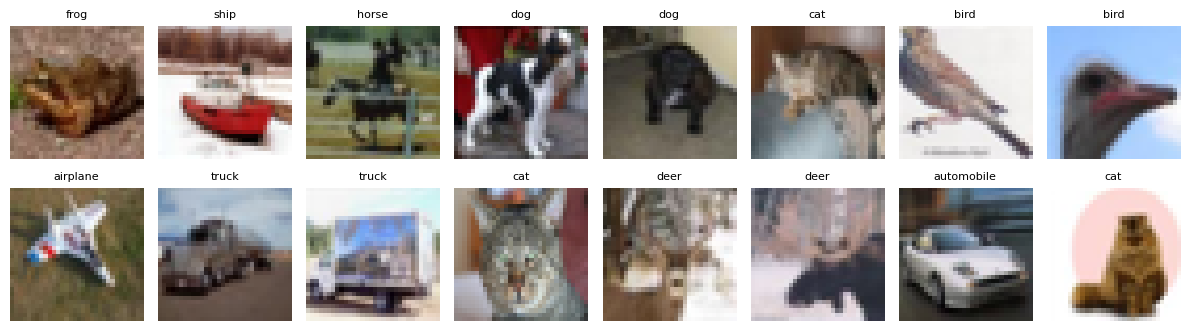

In [5]:
# 1) Train data should now have mean about 0 and std about 1 per channel
print("Train mean after norm:", Xtr.mean(dim=(0, 2, 3)).tolist())
print("Train std after norm: ", Xtr.std(dim=(0, 2, 3)).tolist())
print("Val mean after norm:  ", Xva.mean(dim=(0, 2, 3)).tolist())

# 2) Class balance in each split
print("Train class counts:", torch.bincount(ytr).tolist())
print("Val class counts:  ", torch.bincount(yva).tolist())

# 3) A few training images (un-normalized for display)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, range(16)):
    img = (Xtr[i] * std[0] + mean[0]).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(classes[ytr[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Task 1: Backpropagation

## (a) Layers with explicit forward and backward passes

Linear, ReLU and softmax cross-entropy are implemented from scratch with hand-written forward and backward passes (no autograd) and assembled into an MLP. Each layer caches what it needs in `forward` and returns the gradient with respect to its input in `backward`, storing parameter gradients in `dW` and `db`.

For a Linear layer, $y = xW + b$ with $x \in \mathbb{R}^{N \times D_{in}}$, giving
$\partial L/\partial W = x^\top \,\partial L/\partial y$, $\partial L/\partial b = \sum_n \partial L/\partial y_n$ and $\partial L/\partial x = \partial L/\partial y \; W^\top$.
For ReLU, $\partial L/\partial x = \partial L/\partial y \odot \mathbb{1}[x>0]$.
For softmax cross-entropy with mean over the batch, $\partial L/\partial z = (p - \text{onehot}(y))/N$.

##Layers

In [6]:
class Linear:
    def __init__(self, d_in, d_out, init="he"):
        std = (2.0 / d_in) ** 0.5 if init == "he" else (1.0 / d_in) ** 0.5
        self.W = torch.randn(d_in, d_out, device=device) * std
        self.b = torch.zeros(d_out, device=device)
        self.dW, self.db = None, None

    def forward(self, x):
        self.x = x                       # cache input for backward
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout        # (D_in, D_out)
        self.db = dout.sum(dim=0)        # (D_out,)
        return dout @ self.W.T           # (N, D_in)

    def params(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    def forward(self, x):
        self.mask = (x > 0)
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask

    def params(self):
        return []


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values   # subtract max for stability
        e = torch.exp(z)
        self.p = e / e.sum(dim=1, keepdim=True)
        self.y = y
        N = logits.shape[0]
        return -torch.log(self.p[torch.arange(N, device=logits.device), y] + 1e-12).mean()

    def backward(self):
        N = self.p.shape[0]
        d = self.p.clone()
        d[torch.arange(N, device=d.device), self.y] -= 1
        return d / N

## MLP

In [7]:
class MLP:
    def __init__(self, sizes, init="he"):
        # sizes e.g. [3072, 512, 256, 10]
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init))
            if i < len(sizes) - 2:
                self.layers.append(ReLU())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x, y=None):
        for l in self.layers:
            x = l.forward(x)
        if y is None:
            return x                      # logits
        return x, self.loss_fn.forward(x, y)

    def backward(self):
        d = self.loss_fn.backward()
        for l in reversed(self.layers):
            d = l.backward(d)

    def params(self):
        return [p for l in self.layers for p in l.params()]

In [8]:
set_seed(SEED)
model = MLP([3072, 128, 64, 10])
xb = Xtr[:32].reshape(32, -1).to(device)
yb = ytr[:32].to(device)

logits, loss = model.forward(xb, yb)
model.backward()

print("logits shape:", tuple(logits.shape))
print("loss:", loss.item(), "| ln(10) =", np.log(10))
for l in model.layers:
    if isinstance(l, Linear):
        print("W", tuple(l.W.shape), "dW", tuple(l.dW.shape), "| b", tuple(l.b.shape), "db", tuple(l.db.shape))

logits shape: (32, 10)
loss: 3.0946717262268066 | ln(10) = 2.302585092994046
W (3072, 128) dW (3072, 128) | b (128,) db (128,)
W (128, 64) dW (128, 64) | b (64,) db (64,)
W (64, 10) dW (64, 10) | b (10,) db (10,)


## (b) Gradient verification

The manual gradients are compared against (i) PyTorch autograd and (ii) centred finite differences, $\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$, all in float64. Relative error is $\|a-b\| / (\|a\|+\|b\|)$.

In [9]:
import torch.nn.functional as F

set_seed(SEED)
model = MLP([3072, 64, 32, 10])
for l in model.layers:                       # float64 for accurate checking
    if isinstance(l, Linear):
        l.W, l.b = l.W.double(), l.b.double()
xb = Xtr[:32].reshape(32, -1).to(device).double()
yb = ytr[:32].to(device)

# manual gradients
_, loss = model.forward(xb, yb)
model.backward()
plist = [p for p, _ in model.params()]
manual = [g.clone() for _, g in model.params()]

# autograd gradients (same network written with torch ops)
ps = [p.clone().requires_grad_(True) for p in plist]
h = xb
for i in range(0, len(ps), 2):
    h = h @ ps[i] + ps[i + 1]
    if i < len(ps) - 2:
        h = torch.relu(h)
auto = torch.autograd.grad(F.cross_entropy(h, yb), ps)

def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()

# centred finite differences on 15 random entries per tensor
def loss_fn():
    return model.forward(xb, yb)[1].item()

eps, n_check = 1e-5, 15
g = torch.Generator().manual_seed(SEED)
names = ["W1", "b1", "W2", "b2", "W3", "b3"]
rows = []
for name, p, gm, ga in zip(names, plist, manual, auto):
    flat = p.view(-1)
    idx = torch.randperm(flat.numel(), generator=g)[:n_check]
    fd = torch.zeros(len(idx), dtype=torch.float64, device=device)
    for k, i in enumerate(idx.tolist()):
        old = flat[i].item()
        flat[i] = old + eps; lp = loss_fn()
        flat[i] = old - eps; lm = loss_fn()
        flat[i] = old
        fd[k] = (lp - lm) / (2 * eps)
    gm_s = gm.view(-1)[idx.to(device)]
    rows.append((name,
                 rel_err(gm, ga), torch.allclose(gm, ga, rtol=1e-6, atol=1e-10),
                 rel_err(gm_s, fd), torch.allclose(gm_s, fd, rtol=1e-4, atol=1e-8)))

print(f"{'param':<6}{'rel err vs autograd':>22}{'allclose':>10}{'rel err vs FD':>16}{'allclose':>10}")
for r in rows:
    print(f"{r[0]:<6}{r[1]:>22.2e}{str(r[2]):>10}{r[3]:>16.2e}{str(r[4]):>10}")

param    rel err vs autograd  allclose   rel err vs FD  allclose
W1                  8.18e-17      True        3.04e-10      True
b1                  6.13e-17      True        2.33e-10      True
W2                  4.74e-17      True        3.39e-10      True
b2                  8.57e-17      True        1.88e-10      True
W3                  3.56e-17      True        2.26e-10      True
b3                  6.64e-17      True        1.29e-10      True


**Interpretation.** The manual gradients agree with autograd to a relative error of about 4e-17 to 9e-17 for every weight and bias tensor, which is float64 machine precision, and `torch.allclose` returns True for all of them. This confirms that the hand-written backward passes of Linear, ReLU and softmax cross-entropy compute the exact gradient, not an approximation. Against centred finite differences the relative errors are larger, about 1e-10 to 3e-10 (still `allclose` True). This is expected: a centred difference has truncation error of order ε², and rounding error grows as ε shrinks, so with ε = 1e-5 it cannot reach machine precision. The finite-difference check is independent of autograd and uses only forward passes, so agreeing with both methods rules out a shared mistake. Float64 was used because in float32 the rounding error in the loss (about 1e-7) divided by 2ε would swamp the true gradient and make the finite-difference check meaningless. Finite differences were evaluated on 15 randomly chosen entries per tensor, since checking every entry would require two forward passes per parameter, whereas autograd was compared on every entry.

## (c) Training with SGD

A 3072-512-256-10 MLP (He init) is trained on flattened CIFAR-10 with mini-batch SGD (batch size 128, learning rate 0.05, 15 epochs), using the manual backward pass and a manual update $\theta \leftarrow \theta - \eta\,\nabla_\theta L$.

epoch  1 | train loss 1.7063 | train acc 0.4927 | val loss 1.5818 | val acc 0.4404
epoch  2 | train loss 1.4156 | train acc 0.5511 | val loss 1.5258 | val acc 0.4716
epoch  3 | train loss 1.2887 | train acc 0.5558 | val loss 1.6098 | val acc 0.4494
epoch  4 | train loss 1.1869 | train acc 0.6344 | val loss 1.4891 | val acc 0.4958
epoch  5 | train loss 1.0946 | train acc 0.6515 | val loss 1.5087 | val acc 0.4920
epoch  6 | train loss 1.0136 | train acc 0.6883 | val loss 1.5237 | val acc 0.4960
epoch  7 | train loss 0.9365 | train acc 0.7132 | val loss 1.5777 | val acc 0.4928
epoch  8 | train loss 0.8600 | train acc 0.7155 | val loss 1.6290 | val acc 0.4856
epoch  9 | train loss 0.7922 | train acc 0.7494 | val loss 1.6531 | val acc 0.5036
epoch 10 | train loss 0.7298 | train acc 0.7588 | val loss 1.7585 | val acc 0.4828
epoch 11 | train loss 0.6672 | train acc 0.7846 | val loss 1.8068 | val acc 0.4934
epoch 12 | train loss 0.6107 | train acc 0.8029 | val loss 1.9657 | val acc 0.4910
epoc

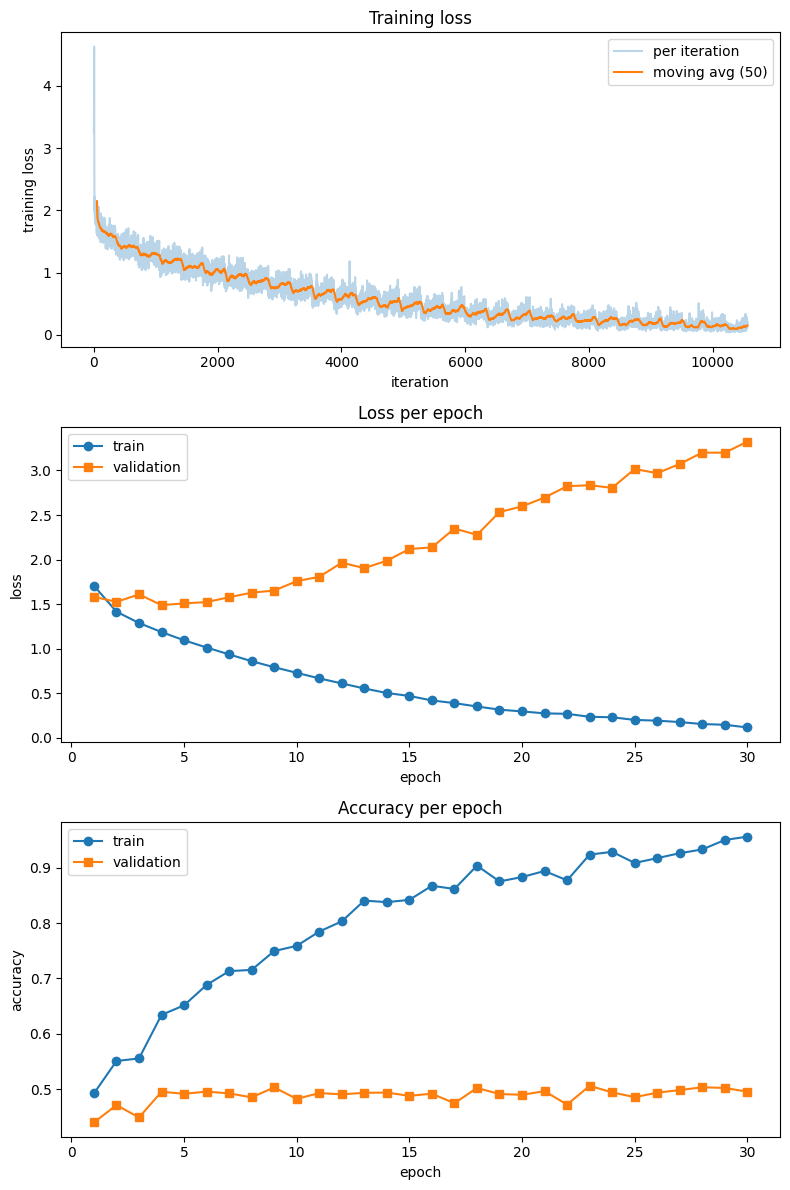


Final validation accuracy: 49.58%


In [10]:
set_seed(SEED)
model = MLP([3072, 512, 256, 10])        # fresh float32 model (the earlier one was float64)

Xtr_f = Xtr.reshape(len(Xtr), -1).to(device)
Xva_f = Xva.reshape(len(Xva), -1).to(device)
ytr_d, yva_d = ytr.to(device), yva.to(device)

lr, epochs, bs = 0.1, 30, 128
iter_loss, ep_train_loss, ep_val_loss, ep_val_acc, ep_train_acc = [], [], [], [], []

def evaluate(X, y):
    logits, loss = model.forward(X, y)
    return loss.item(), (logits.argmax(1) == y).float().mean().item()

gen = torch.Generator(device="cpu").manual_seed(SEED)
for ep in range(epochs):
    perm = torch.randperm(len(Xtr_f), generator=gen).to(device)
    running = 0.0
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        _, loss = model.forward(Xtr_f[idx], ytr_d[idx])
        model.backward()
        for p, g in model.params():       # manual SGD step
            p.sub_(lr * g)
        iter_loss.append(loss.item())
        running += loss.item() * len(idx)
    ep_train_loss.append(running / len(perm))
    vl, va = evaluate(Xva_f, yva_d)
    _, ta = evaluate(Xtr_f, ytr_d)
    ep_val_loss.append(vl); ep_val_acc.append(va); ep_train_acc.append(ta)
    print(f"epoch {ep+1:2d} | train loss {ep_train_loss[-1]:.4f} | train acc {ta:.4f} | val loss {vl:.4f} | val acc {va:.4f}")

# plots
fig, ax = plt.subplots(3, 1, figsize=(8, 12))
k = 50
smooth = np.convolve(iter_loss, np.ones(k) / k, mode="valid")
ax[0].plot(iter_loss, alpha=0.3, label="per iteration")
ax[0].plot(np.arange(k - 1, len(iter_loss)), smooth, label=f"moving avg ({k})")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("training loss"); ax[0].set_title("Training loss"); ax[0].legend()

ax[1].plot(range(1, epochs + 1), ep_train_loss, "o-", label="train")
ax[1].plot(range(1, epochs + 1), ep_val_loss, "s-", label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].set_title("Loss per epoch"); ax[1].legend()

ax[2].plot(range(1, epochs + 1), ep_train_acc, "o-", label="train")
ax[2].plot(range(1, epochs + 1), ep_val_acc, "s-", label="validation")
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("accuracy"); ax[2].set_title("Accuracy per epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"\nFinal validation accuracy: {ep_val_acc[-1]*100:.2f}%")

**Interpretation.** With lr = 0.1, batch size 128 and 30 epochs, training loss falls from 1.71 to 0.12 and training accuracy rises from 49.3% to 95.6%, while validation accuracy stays around 48-51% from epoch 4 onward and ends at 49.58% (peak 50.64% at epoch 23). This is far above the 10% chance level but about 46 points below training accuracy, so the MLP (about 1.7M parameters) is overfitting: it memorizes the 45k training images instead of learning features that generalize. The validation loss is lowest at epoch 2 (1.53) and then rises to 3.32 while the training loss keeps falling, because the network becomes increasingly confident on the validation images it misclassifies, and cross-entropy penalizes confident errors heavily. Validation accuracy changes much less than validation loss since accuracy only counts whether the argmax is correct. The per-iteration loss curve is noisy because each mini-batch gives only a noisy estimate of the full gradient. An MLP on flattened pixels plateaus near 50% because it treats every pixel as an independent input and has no notion of spatial structure or translation invariance, which motivates the CNNs used in later tasks.

## (d) Gradient norms across depth: sigmoid vs ReLU

A 10-layer MLP (3072-256×9-10) is built with ReLU and with sigmoid. At initialization, one backward pass on 128 training images gives the norm of $\partial L/\partial W$ for each layer.

layer            ReLU + He init   Sigmoid + Xavier init       Sigmoid + He init
1                     5.619e+00               1.398e-05               1.995e-04
2                     1.997e+00               2.024e-05               2.828e-04
3                     2.268e+00               8.536e-05               9.078e-04
4                     2.418e+00               3.628e-04               2.877e-03
5                     2.632e+00               1.442e-03               8.524e-03
6                     2.886e+00               6.110e-03               2.753e-02
7                     3.169e+00               2.289e-02               7.588e-02
8                     3.168e+00               9.436e-02               2.326e-01
9                     2.991e+00               4.211e-01               7.598e-01
10                    3.187e+00               1.715e+00               2.334e+00


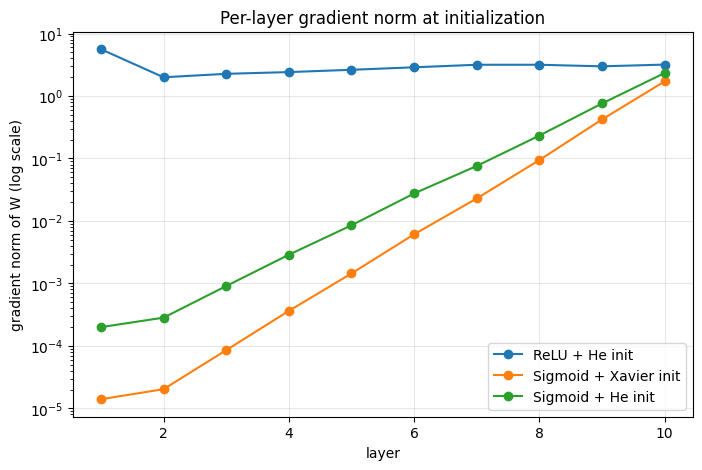

In [11]:
class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out
    def backward(self, dout):
        return dout * self.out * (1 - self.out)
    def params(self):
        return []

def make_deep(act, init):
    m = MLP([3072] + [256] * 9 + [10], init)       # 10 Linear layers
    if act == "sigmoid":
        m.layers = [Sigmoid() if isinstance(l, ReLU) else l for l in m.layers]
    return m

xb = Xtr[:128].reshape(128, -1).to(device)
yb = ytr[:128].to(device)

configs = [("ReLU + He init", "relu", "he"),
           ("Sigmoid + Xavier init", "sigmoid", "xavier"),
           ("Sigmoid + He init", "sigmoid", "he")]
norms = {}
for name, act, init in configs:
    set_seed(SEED)
    m = make_deep(act, init)
    _, loss = m.forward(xb, yb)
    m.backward()
    norms[name] = [l.dW.norm().item() for l in m.layers if isinstance(l, Linear)]

print(f"{'layer':<7}" + "".join(f"{n:>24}" for n in norms))
for i in range(10):
    print(f"{i+1:<7}" + "".join(f"{norms[n][i]:>24.3e}" for n in norms))

plt.figure(figsize=(8, 5))
for n, v in norms.items():
    plt.semilogy(range(1, 11), v, "o-", label=n)
plt.xlabel("layer")
plt.ylabel("gradient norm of W (log scale)")
plt.title("Per-layer gradient norm at initialization")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretation.** With ReLU and He initialization the per-layer gradient norm stays between about 2.0 and 5.6 across all ten layers, so the backward signal neither vanishes nor explodes. With sigmoid, the gradient norm drops steadily from the output side to the input side: with Xavier initialization it falls from 1.7 at layer 10 to 1.4e-5 at layer 1 (about five orders of magnitude, roughly 4x per layer), and with He initialization from 2.3 to 2.0e-4. This is the vanishing gradient problem. The derivative of the sigmoid is σ(x)(1−σ(x)) ≤ 0.25, so during backpropagation each sigmoid layer multiplies the gradient by at most 0.25 (times the weight matrix), and over nine such layers the signal shrinks geometrically. ReLU has derivative 1 for active units and 0 otherwise, so it does not shrink the gradient where it is active, and He initialization (variance 2/fan_in) compensates for ReLU zeroing about half of the units, which keeps the signal scale constant from layer to layer. The He-initialized sigmoid network vanishes slightly less than the Xavier one because larger weights partly offset the 0.25 factor, but it still vanishes, which shows that the cause is the sigmoid activation and not only a poor initialization choice. The practical consequence is that the early layers of a deep sigmoid network